# Round 4 — Data Exploration
Same products as Round 3 (VELVETFRUIT_EXTRACT, HYDROGEL_PACK, VEV_4000–6500). Investigating price levels, bot behavior, and any structural changes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

DATA = Path('ROUND_4')
DAYS = [1, 2, 3]

# ── load prices ──────────────────────────────────────────────────────────────
prices_frames = []
for d in DAYS:
    df = pd.read_csv(DATA / f'prices_round_4_day_{d}.csv', sep=';')
    df['abs_ts'] = (d - 1) * 1_000_000 + df['timestamp']
    prices_frames.append(df)
prices = pd.concat(prices_frames, ignore_index=True)

# ── load trades ──────────────────────────────────────────────────────────────
trades_frames = []
for d in DAYS:
    df = pd.read_csv(DATA / f'trades_round_4_day_{d}.csv', sep=';')
    df['day'] = d
    df['abs_ts'] = (d - 1) * 1_000_000 + df['timestamp']
    trades_frames.append(df)
trades = pd.concat(trades_frames, ignore_index=True)

PRODUCTS = sorted(prices['product'].unique())
BOTS     = sorted(set(trades['buyer'].unique()) | set(trades['seller'].unique()))
print('Products:', PRODUCTS)
print('Bots    :', BOTS)
print(f'Price rows: {len(prices):,}   Trade rows: {len(trades):,}')

Products: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Bots    : ['Mark 01', 'Mark 14', 'Mark 22', 'Mark 38', 'Mark 49', 'Mark 55', 'Mark 67']
Price rows: 360,000   Trade rows: 4,281


## Mid-price per product — all days
Vertical dashed lines mark day boundaries. Bot trades overlaid as scatter points (coloured by bot).

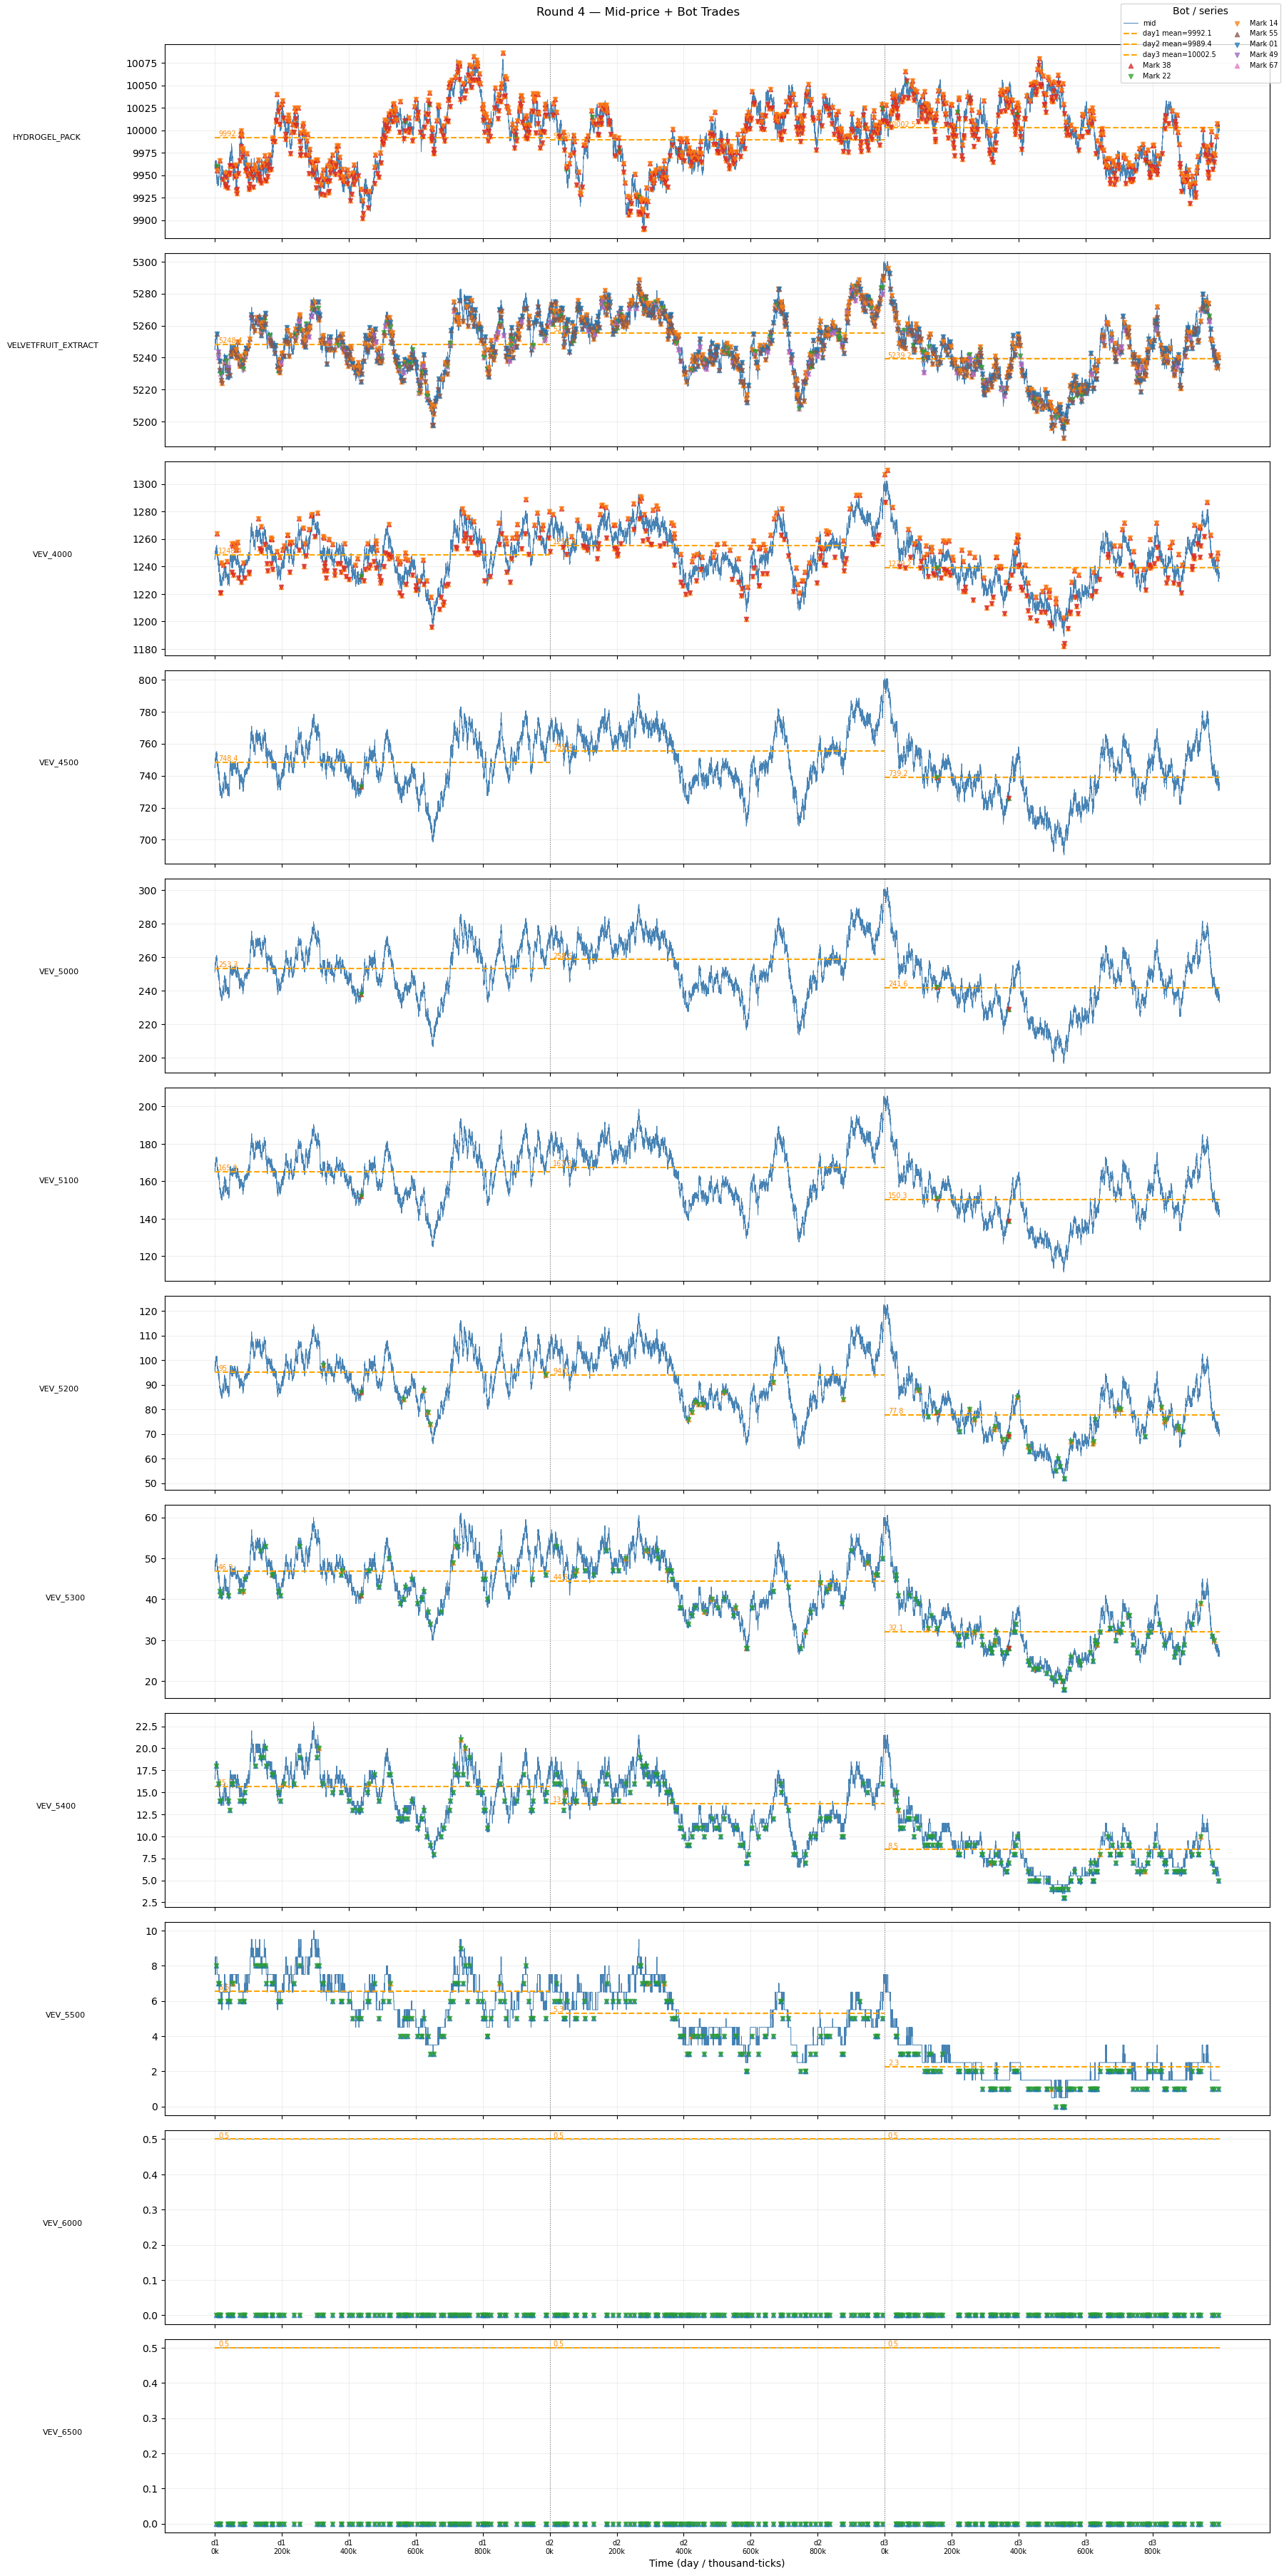

In [2]:
# colour palette for bots
BOT_COLORS = plt.cm.tab10.colors
bot_color  = {b: BOT_COLORS[i % len(BOT_COLORS)] for i, b in enumerate(BOTS)}

# day boundary x-positions
day_boundaries = [(d - 1) * 1_000_000 for d in DAYS[1:]]  # start of day 2, 3

# x-tick positions: every 200 000 ticks, labelled as day/ts
def make_xticks(max_abs_ts, step=200_000):
    positions = list(range(0, int(max_abs_ts) + 1, step))
    labels = []
    for p in positions:
        d = p // 1_000_000 + 1
        t = p % 1_000_000
        labels.append(f'd{d}\n{t//1000}k')
    return positions, labels

MAX_TS = prices['abs_ts'].max()

fig, axes = plt.subplots(len(PRODUCTS), 1, figsize=(18, 3 * len(PRODUCTS)), sharex=True)
if len(PRODUCTS) == 1:
    axes = [axes]

for ax, prod in zip(axes, PRODUCTS):
    sub = prices[prices['product'] == prod]

    # ── mid-price line ────────────────────────────────────────────────────
    ax.plot(sub['abs_ts'], sub['mid_price'], lw=0.7, color='steelblue', label='mid')

    # ── daily mean highlighted ────────────────────────────────────────────
    for d in DAYS:
        dsub = sub[sub['day'] == d] if 'day' in sub.columns else sub[
            (sub['abs_ts'] >= (d-1)*1_000_000) & (sub['abs_ts'] < d*1_000_000)]
        if dsub.empty:
            continue
        dmean = dsub['mid_price'].mean()
        x0 = (d - 1) * 1_000_000
        x1 = d * 1_000_000
        ax.hlines(dmean, x0, x1, colors='orange', lw=1.5, ls='--',
                  label=f'day{d} mean={dmean:.1f}' if prod == PRODUCTS[0] else '')
        ax.text(x0 + 10_000, dmean, f'{dmean:.1f}', color='darkorange',
                va='bottom', fontsize=7)

    # ── bot trades ────────────────────────────────────────────────────────
    prod_trades = trades[trades['symbol'] == prod]
    plotted_bots = set()
    for _, row in prod_trades.iterrows():
        for role, bot in [('buy', row['buyer']), ('sell', row['seller'])]:
            label = bot if bot not in plotted_bots else None
            marker = '^' if role == 'buy' else 'v'
            ax.scatter(row['abs_ts'], row['price'],
                       color=bot_color[bot], marker=marker, s=20, alpha=0.7,
                       label=label, zorder=3)
            if label:
                plotted_bots.add(bot)

    # ── day boundary lines ─────────────────────────────────────────────────
    for xb in day_boundaries:
        ax.axvline(xb, color='grey', lw=0.8, ls=':')

    ax.set_ylabel(prod, fontsize=8, rotation=0, labelpad=80, va='center')
    ax.yaxis.set_label_position('left')
    ax.grid(True, alpha=0.2)

# shared x-axis labels
pos, lbl = make_xticks(MAX_TS)
axes[-1].set_xticks(pos)
axes[-1].set_xticklabels(lbl, fontsize=7)
axes[-1].set_xlabel('Time (day / thousand-ticks)')

# legend with bots (from last axis that has them)
handles, labels = [], []
for ax in axes:
    h, l = ax.get_legend_handles_labels()
    for hh, ll in zip(h, l):
        if ll not in labels:
            handles.append(hh); labels.append(ll)
fig.legend(handles, labels, loc='upper right', fontsize=7, ncol=2,
           title='Bot / series', framealpha=0.8)

plt.suptitle('Round 4 — Mid-price + Bot Trades', fontsize=12, y=1.002)
plt.tight_layout()
plt.savefig('round4_all_products.png', dpi=150, bbox_inches='tight')
plt.show()

## Per-day summary statistics

In [3]:
summary_rows = []
for prod in PRODUCTS:
    sub = prices[prices['product'] == prod]
    for d in DAYS:
        dsub = sub[(sub['abs_ts'] >= (d-1)*1_000_000) & (sub['abs_ts'] < d*1_000_000)]
        if dsub.empty:
            continue
        mp = dsub['mid_price']
        summary_rows.append({
            'product': prod, 'day': d,
            'mean': round(mp.mean(), 2),
            'std':  round(mp.std(),  2),
            'min':  round(mp.min(),  2),
            'max':  round(mp.max(),  2),
            'range': round(mp.max() - mp.min(), 2),
        })

summary = pd.DataFrame(summary_rows)
pd.set_option('display.max_rows', 100)
summary.set_index(['product','day'])

mean    std     min      max  range
product             day                                         
HYDROGEL_PACK       1     9992.06  37.61  9908.5  10079.0  170.5
                    2     9989.40  31.62  9891.0  10051.0  160.0
                    3    10002.50  32.95  9923.0  10081.0  158.0
VELVETFRUIT_EXTRACT 1     5248.39  14.61  5198.0   5283.0   85.0
                    2     5255.39  16.99  5207.0   5300.0   93.0
                    3     5239.16  18.60  5191.5   5300.0  108.5
VEV_4000            1     1248.41  14.63  1198.0   1283.0   85.0
                    2     1255.40  17.00  1207.0   1300.0   93.0
                    3     1239.16  18.63  1189.0   1302.0  113.0
VEV_4500            1      748.41  14.63   698.5    783.0   84.5
                    2      755.40  16.99   708.5    799.5   91.0
                    3      739.16  18.62   690.5    800.5  110.0
VEV_5000            1      253.26  13.58   206.5    285.5   79.0
                    2      258.54  16.15   213.5    300.5   87.0
                    3      241.63  17.86   196.5    301.5  105.0
VEV_5100            1      164.98  11.94   125.0    193.5   68.5
                    2      167.33  14.81   127.5    205.5   78.0
                    3      150.28  15.74   111.5    205.5   94.0
VEV_5200            1       95.13   8.66    66.0    116.0   50.0
                    2       94.05  11.50    64.0    122.5   58.5
                    3       77.81  11.78    51.0    122.5   71.5
VEV_5300            1       46.91   5.47    30.0     61.0   31.0
                    2       44.48   7.06    26.5     60.5   34.0
                    3       32.14   6.75    18.0     60.5   42.5
VEV_5400            1       15.65   2.68     7.5     23.0   15.5
                    2       13.73   3.01     6.5     21.5   15.0
                    3        8.50   2.83     3.5     21.5   18.0
VEV_5500            1        6.57   1.33     3.0     10.0    7.0
                    2        5.29   1.40     2.5      9.5    7.0
                    3        2.26   1.03     0.5      7.5    7.0
VEV_6000            1        0.50   0.00     0.5      0.5    0.0
                    2        0.50   0.00     0.5      0.5    0.0
                    3        0.50   0.00     0.5      0.5    0.0
VEV_6500            1        0.50   0.00     0.5      0.5    0.0
                    2        0.50   0.00     0.5      0.5    0.0
                    3        0.50   0.00     0.5      0.5    0.0

## Bot trade volume by product and day

In [4]:
tv = (trades.groupby(['day','symbol'])['quantity']
      .sum().reset_index()
      .pivot(index='symbol', columns='day', values='quantity')
      .fillna(0).astype(int))
tv.columns = [f'day{c}' for c in tv.columns]
tv['total'] = tv.sum(axis=1)
tv.sort_values('total', ascending=False)

,day1,day2,day3,total
symbol,,,,
VELVETFRUIT_EXTRACT,2685,2895,2623,8203
HYDROGEL_PACK,1485,1244,1367,4096
VEV_6000,345,337,423,1105
VEV_6500,345,337,423,1105
VEV_5500,321,335,413,1069
VEV_5400,286,283,390,959
VEV_4000,333,256,287,876
VEV_5300,130,162,256,548
VEV_5200,22,26,114,162


## Bot activity — who trades what

In [5]:
# combine buyer + seller into single 'bot' column
buy_side  = trades[['symbol','buyer','quantity']].rename(columns={'buyer':'bot'})
sell_side = trades[['symbol','seller','quantity']].rename(columns={'seller':'bot'})
all_sides = pd.concat([buy_side, sell_side])

bot_vol = (all_sides.groupby(['bot','symbol'])['quantity']
           .sum().reset_index()
           .pivot(index='bot', columns='symbol', values='quantity')
           .fillna(0).astype(int))
bot_vol

symbol,HYDROGEL_PACK,VELVETFRUIT_EXTRACT,VEV_4000,VEV_4500,VEV_5000,VEV_5100,VEV_5200,VEV_5300,VEV_5400,VEV_5500,VEV_6000,VEV_6500
bot,,,,,,,,,,,,
Mark 01,0,2792,0,0,0,0,34,439,911,1042,1105,1105
Mark 14,4022,3524,870,0,0,0,122,105,48,27,0,0
Mark 22,74,843,6,6,6,6,162,548,959,1069,1105,1105
Mark 38,4096,0,876,6,6,6,6,4,0,0,0,0
Mark 49,0,1186,0,0,0,0,0,0,0,0,0,0
Mark 55,0,6551,0,0,0,0,0,0,0,0,0,0
Mark 67,0,1510,0,0,0,0,0,0,0,0,0,0


## Spread analysis — bid-ask spread per product per day

In [6]:
prices['spread'] = prices['ask_price_1'] - prices['bid_price_1']
spread_stats = (prices.groupby(['product','day'])['spread']
                .agg(['mean','median','std'])
                .round(2))
spread_stats

mean  median   std
product             day                     
HYDROGEL_PACK       1    15.73    16.0  1.44
                    2    15.74    16.0  1.41
                    3    15.72    16.0  1.49
VELVETFRUIT_EXTRACT 1     4.98     5.0  0.85
                    2     4.99     5.0  0.85
                    3     4.98     5.0  0.85
VEV_4000            1    20.77    21.0  1.51
                    2    20.90    21.0  1.48
                    3    20.59    21.0  1.63
VEV_4500            1    15.81    16.0  1.20
                    2    15.96    16.0  1.20
                    3    15.61    16.0  1.31
VEV_5000            1     6.01     6.0  0.64
                    2     6.12     6.0  0.68
                    3     5.76     6.0  0.70
VEV_5100            1     4.26     4.0  0.58
                    2     4.31     4.0  0.59
                    3     3.96     4.0  0.58
VEV_5200            1     2.88     3.0  0.43
                    2     2.86     3.0  0.48
                    3     2.54     3.0  0.54
VEV_5300            1     2.11     2.0  0.37
                    2     2.05     2.0  0.39
                    3     1.76     2.0  0.45
VEV_5400            1     1.39     1.0  0.49
                    2     1.33     1.0  0.47
                    3     1.20     1.0  0.40
VEV_5500            1     1.15     1.0  0.36
                    2     1.12     1.0  0.32
                    3     1.06     1.0  0.23
VEV_6000            1     1.00     1.0  0.00
                    2     1.00     1.0  0.00
                    3     1.00     1.0  0.00
VEV_6500            1     1.00     1.0  0.00
                    2     1.00     1.0  0.00
                    3     1.00     1.0  0.00

## Options deep-dive — mid-price all strikes overlaid

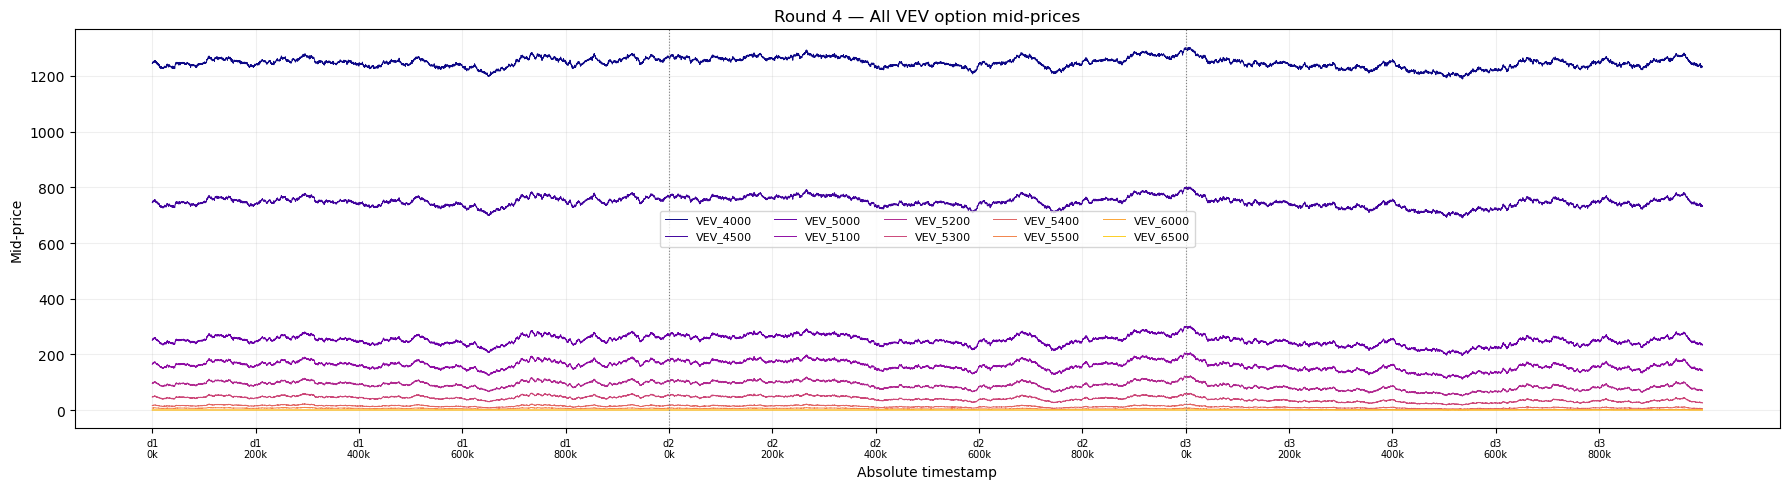

In [7]:
OPT_STRIKES = [4000, 4500, 5000, 5100, 5200, 5300, 5400, 5500, 6000, 6500]
OPT_PRODS   = [f'VEV_{k}' for k in OPT_STRIKES]

fig, ax = plt.subplots(figsize=(18, 5))
cmap = plt.cm.plasma

for i, prod in enumerate(OPT_PRODS):
    sub = prices[prices['product'] == prod]
    color = cmap(i / len(OPT_PRODS))
    ax.plot(sub['abs_ts'], sub['mid_price'], lw=0.7, color=color, label=prod)

# day boundaries
for xb in day_boundaries:
    ax.axvline(xb, color='grey', lw=0.8, ls=':')

ax.set_xlabel('Absolute timestamp')
ax.set_ylabel('Mid-price')
ax.set_title('Round 4 — All VEV option mid-prices')
ax.legend(fontsize=8, ncol=5)
ax.grid(True, alpha=0.2)

pos, lbl = make_xticks(MAX_TS)
ax.set_xticks(pos); ax.set_xticklabels(lbl, fontsize=7)
plt.tight_layout()
plt.show()

## VELVETFRUIT vs HYDROGEL correlation

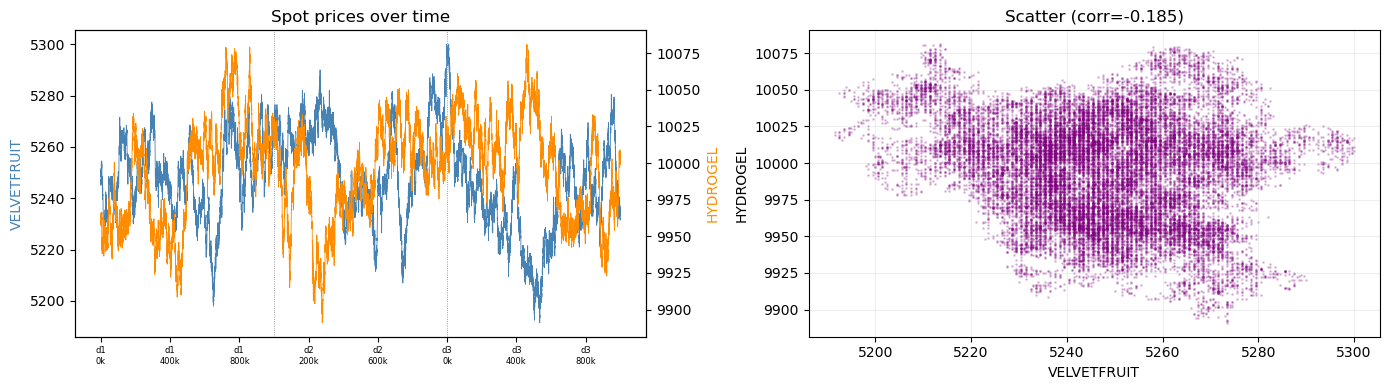

Pearson correlation: -0.1851


In [8]:
vev  = prices[prices['product']=='VELVETFRUIT_EXTRACT'][['abs_ts','mid_price']].set_index('abs_ts').rename(columns={'mid_price':'VEV'})
hyd  = prices[prices['product']=='HYDROGEL_PACK'][['abs_ts','mid_price']].set_index('abs_ts').rename(columns={'mid_price':'HYD'})
spot = vev.join(hyd, how='inner')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# time series
ax = axes[0]
ax2 = ax.twinx()
ax.plot(spot.index,  spot['VEV'], color='steelblue', lw=0.6, label='VELVETFRUIT')
ax2.plot(spot.index, spot['HYD'], color='darkorange', lw=0.6, label='HYDROGEL')
for xb in day_boundaries:
    ax.axvline(xb, color='grey', lw=0.6, ls=':')
ax.set_ylabel('VELVETFRUIT', color='steelblue')
ax2.set_ylabel('HYDROGEL', color='darkorange')
ax.set_title('Spot prices over time')
ax.set_xticks(pos[::2]); ax.set_xticklabels(lbl[::2], fontsize=6)

# scatter
axes[1].scatter(spot['VEV'], spot['HYD'], s=1, alpha=0.2, color='purple')
corr = spot.corr().iloc[0,1]
axes[1].set_xlabel('VELVETFRUIT'); axes[1].set_ylabel('HYDROGEL')
axes[1].set_title(f'Scatter (corr={corr:.3f})')
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.show()
print(f'Pearson correlation: {corr:.4f}')

## Option mid-prices vs VELVETFRUIT spot — check static FV anchor drift

In [9]:
# Round 3 calibrated static FVs
STATIC_FV = {
    'VEV_4000': 1250.1,
    'VEV_4500':  750.1,
    'VEV_5000':  255.0,
    'VEV_5100':  166.8,
    'VEV_5200':   95.6,
    'VEV_5300':   46.8,
    'VEV_5400':   15.95,
    'VEV_5500':    6.64,
}

stats_rows = []
for prod, fv in STATIC_FV.items():
    sub = prices[prices['product'] == prod]['mid_price']
    if sub.empty:
        continue
    stats_rows.append({
        'product': prod,
        'r3_static_fv': fv,
        'r4_mean': round(sub.mean(), 2),
        'r4_median': round(sub.median(), 2),
        'r4_std': round(sub.std(), 2),
        'drift': round(sub.mean() - fv, 2),
        'drift_pct': round((sub.mean() - fv) / fv * 100, 2),
    })

drift_df = pd.DataFrame(stats_rows).set_index('product')
drift_df.style.background_gradient(subset=['drift_pct'], cmap='RdYlGn_r')

,r3_static_fv,r4_mean,r4_median,r4_std,drift,drift_pct
product,,,,,,
VEV_4000,1250.100000,1247.660000,1247.500000,18.100000,-2.440000,-0.200000
VEV_4500,750.100000,747.660000,748.000000,18.090000,-2.440000,-0.330000
VEV_5000,255.000000,251.140000,252.000000,17.460000,-3.860000,-1.510000
VEV_5100,166.800000,160.860000,161.500000,16.130000,-5.940000,-3.560000
VEV_5200,95.600000,88.990000,89.500000,13.350000,-6.610000,-6.910000
VEV_5300,46.800000,41.180000,42.000000,9.140000,-5.620000,-12.020000
VEV_5400,15.950000,12.630000,12.500000,4.150000,-3.320000,-20.820000
VEV_5500,6.640000,4.710000,4.500000,2.210000,-1.930000,-29.100000


## Bot trade price distribution per strike

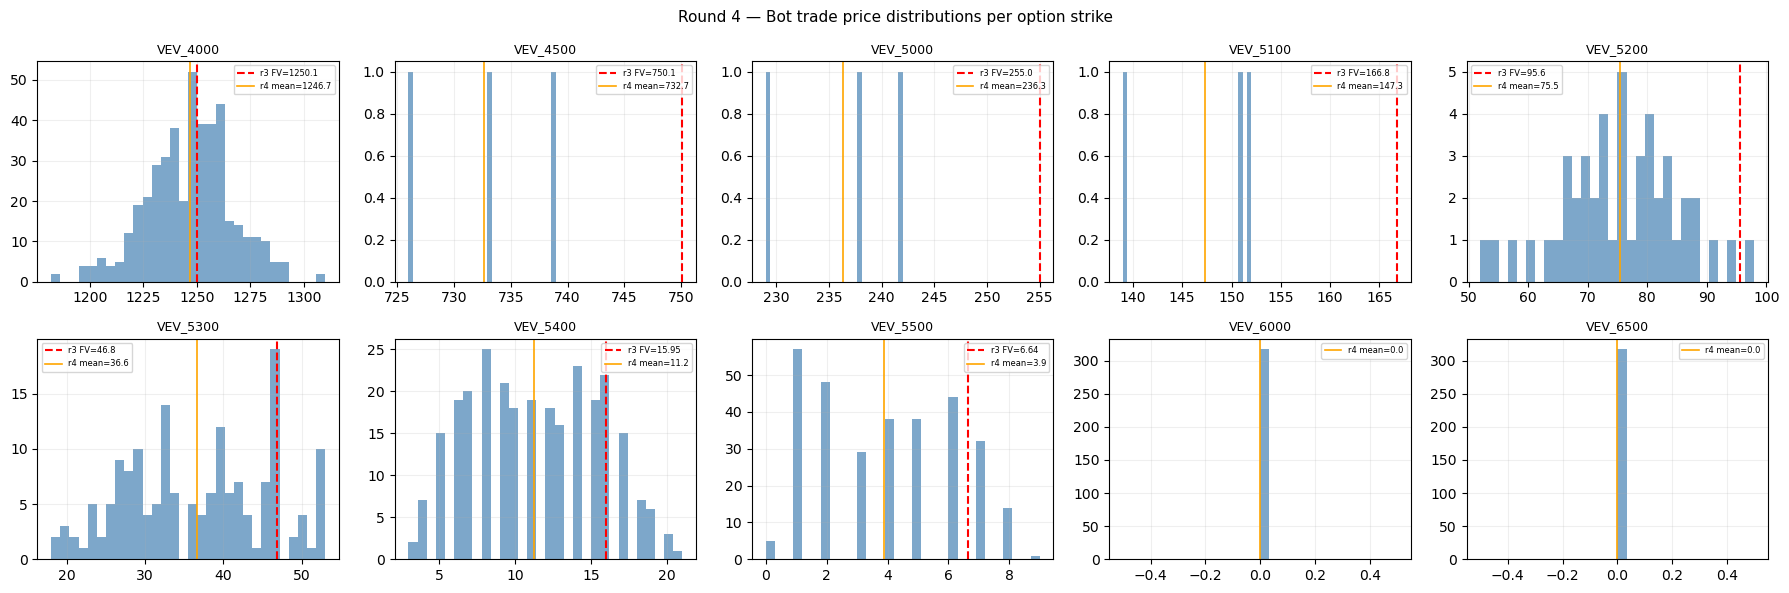

In [10]:
opt_trades = trades[trades['symbol'].isin(OPT_PRODS)]

fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharey=False)
axes = axes.flatten()

for ax, prod in zip(axes, OPT_PRODS):
    sub = opt_trades[opt_trades['symbol'] == prod]
    if sub.empty:
        ax.set_title(prod + ' (no trades)')
        ax.set_visible(False)
        continue

    # histogram of trade prices
    ax.hist(sub['price'], bins=30, color='steelblue', alpha=0.7, edgecolor='none')

    # static FV line if available
    if prod in STATIC_FV:
        ax.axvline(STATIC_FV[prod], color='red', lw=1.5, ls='--', label=f'r3 FV={STATIC_FV[prod]}')

    mean_price = sub['price'].mean()
    ax.axvline(mean_price, color='orange', lw=1.2, ls='-', label=f'r4 mean={mean_price:.1f}')
    ax.set_title(prod, fontsize=9)
    ax.legend(fontsize=6)
    ax.grid(True, alpha=0.2)

plt.suptitle('Round 4 — Bot trade price distributions per option strike', fontsize=11)
plt.tight_layout()
plt.show()

## Bot net position by strike (buy - sell volume)

In [11]:
buy_vol  = trades.groupby(['buyer','symbol'])['quantity'].sum().rename('buy')
sell_vol = trades.groupby(['seller','symbol'])['quantity'].sum().rename('sell')
net = pd.concat([buy_vol, sell_vol], axis=1).fillna(0)
net['net'] = net['buy'] - net['sell']
net = net.reset_index().rename(columns={'buyer':'bot','level_0':'bot'})
# fix multi-index
buy_vol2  = trades.groupby(['buyer','symbol'])['quantity'].sum().reset_index()
sell_vol2 = trades.groupby(['seller','symbol'])['quantity'].sum().reset_index()
buy_vol2.columns  = ['bot','symbol','buy']
sell_vol2.columns = ['bot','symbol','sell']
net2 = buy_vol2.merge(sell_vol2, on=['bot','symbol'], how='outer').fillna(0)
net2['net'] = net2['buy'] - net2['sell']
net_pivot = net2.pivot(index='bot', columns='symbol', values='net').fillna(0).astype(int)
net_pivot

symbol,HYDROGEL_PACK,VELVETFRUIT_EXTRACT,VEV_4000,VEV_4500,VEV_5000,VEV_5100,VEV_5200,VEV_5300,VEV_5400,VEV_5500,VEV_6000,VEV_6500
bot,,,,,,,,,,,,
Mark 01,0,42,0,0,0,0,34,439,911,1042,1105,1105
Mark 14,-44,-2,46,0,0,0,122,105,48,27,0,0
Mark 22,10,-551,0,0,0,0,-156,-542,-959,-1069,-1105,-1105
Mark 38,34,0,-46,0,0,0,0,-2,0,0,0,0
Mark 49,0,-956,0,0,0,0,0,0,0,0,0,0
Mark 55,0,-43,0,0,0,0,0,0,0,0,0,0
Mark 67,0,1510,0,0,0,0,0,0,0,0,0,0


## Bot role summary
Based on net positions:
- **Mark 01** — systematic option BUYER (long 5200–6500, zero spot activity)
- **Mark 22** — systematic option SELLER (short mirror of Mark 01) + big VEV seller
- **Mark 67** — massive VEV directional BUYER (+1510 net, options inactive)
- **Mark 49** — big VEV directional SELLER (-956)
- **Mark 55** — high-volume VEV market maker (6551 total, net -43)
- **Mark 14** — HYD market maker + small option buyer on lower strikes
- **Mark 38** — HYD market maker (mirror of Mark 14)

## Bot pairing matrix — who trades with whom

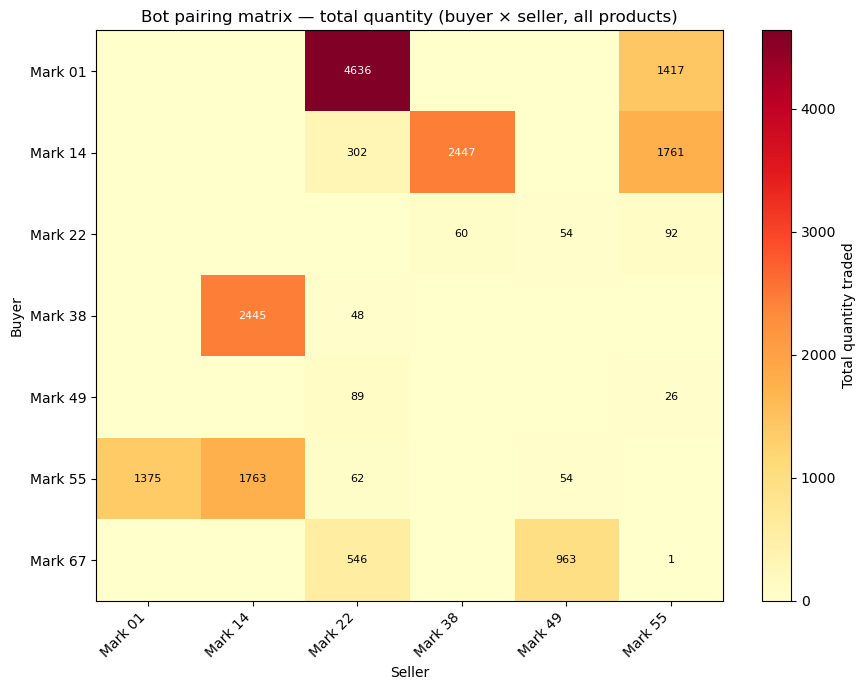


VELVETFRUIT_EXTRACT:
seller   Mark 01  Mark 14  Mark 22  Mark 49  Mark 55
buyer                                               
Mark 01        0        0        0        0     1417
Mark 14        0        0        0        0     1761
Mark 22        0        0        0       54       92
Mark 49        0        0       89        0       26
Mark 55     1375     1763       62       54        0
Mark 67        0        0      546      963        1

HYDROGEL_PACK:
seller   Mark 14  Mark 22  Mark 38
buyer                             
Mark 14        0        0     1989
Mark 22        0        0       42
Mark 38     2033       32        0


In [12]:
pair_counts = (trades.groupby(['buyer','seller'])['quantity']
               .sum().reset_index()
               .pivot(index='buyer', columns='seller', values='quantity')
               .fillna(0).astype(int))

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(pair_counts.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(pair_counts.columns))); ax.set_xticklabels(pair_counts.columns, rotation=45, ha='right')
ax.set_yticks(range(len(pair_counts.index)));   ax.set_yticklabels(pair_counts.index)
for i in range(len(pair_counts.index)):
    for j in range(len(pair_counts.columns)):
        v = pair_counts.values[i, j]
        if v > 0:
            ax.text(j, i, str(v), ha='center', va='center', fontsize=8,
                    color='white' if v > pair_counts.values.max() * 0.5 else 'black')
plt.colorbar(im, ax=ax, label='Total quantity traded')
ax.set_xlabel('Seller'); ax.set_ylabel('Buyer')
ax.set_title('Bot pairing matrix — total quantity (buyer × seller, all products)')
plt.tight_layout()
plt.show()

# per-product version for spot
for prod in ['VELVETFRUIT_EXTRACT', 'HYDROGEL_PACK']:
    sub = trades[trades['symbol'] == prod]
    pm = (sub.groupby(['buyer','seller'])['quantity']
          .sum().reset_index()
          .pivot(index='buyer', columns='seller', values='quantity')
          .fillna(0).astype(int))
    print(f'\n{prod}:')
    print(pm.to_string())

## Bot aggression — trade price vs bid/ask
Does each bot cross the spread (aggressive) or sit inside it (passive)?
`+1.0` = bought at ask / sold at bid (full aggressor). `0` = traded exactly at mid.

Aggression score: +1=full aggressor (crossed spread), 0=passive at mid

         buy_trades  buy_agg_mean  sell_trades  sell_agg_mean
bot                                                          
Mark 01        1599        -1.000          244         -1.000
Mark 14        1127        -0.998         1045         -1.000
Mark 22          42        -0.524         1542          0.860
Mark 38         733         1.000          745          1.000
Mark 49          17        -1.137          105         -1.057
Mark 55         598         1.000          600          1.000
Mark 67         165         0.988            0            NaN


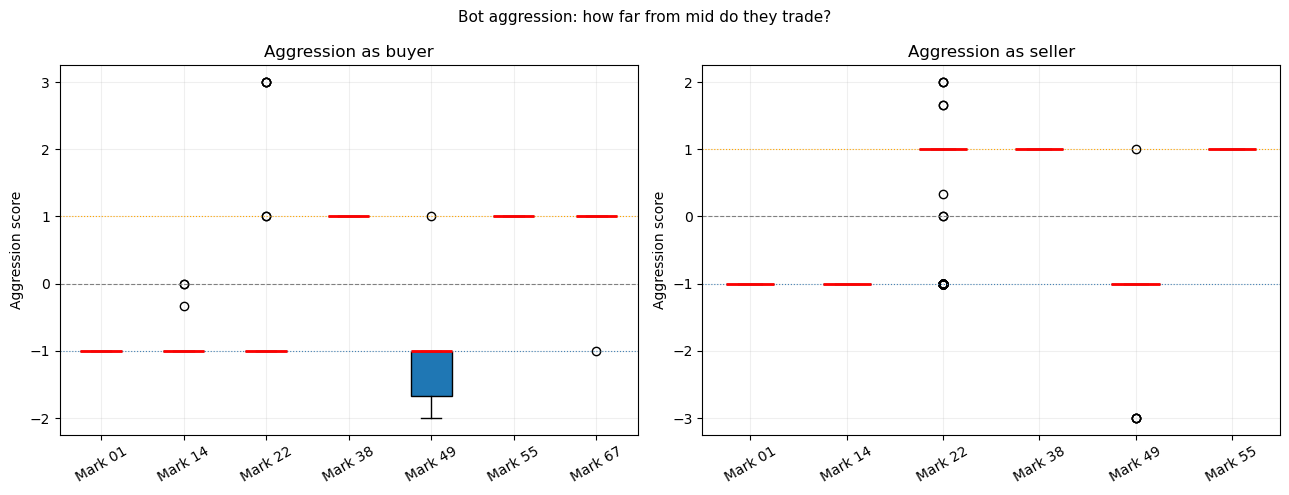

In [13]:
# Join each trade with the nearest price tick to get bid/ask/mid at trade time
price_snap = prices[['abs_ts','product','mid_price','bid_price_1','ask_price_1','spread']].copy()

enriched_parts = []
for sym in trades['symbol'].unique():
    t = trades[trades['symbol'] == sym].copy()
    p = price_snap[price_snap['product'] == sym].sort_values('abs_ts')
    m = pd.merge_asof(t.sort_values('abs_ts'), p, on='abs_ts', direction='nearest')
    enriched_parts.append(m)
te = pd.concat(enriched_parts, ignore_index=True)

# Aggression score for the BUYER:
#   (trade_price - mid) / (ask - mid)  → +1 = paid full ask, -1 = received full bid
half_spread = (te['ask_price_1'] - te['bid_price_1']) / 2
te['buyer_aggression']  = (te['price'] - te['mid_price']) / half_spread.replace(0, 1)
te['seller_aggression'] = -te['buyer_aggression']  # inverse

# Per-bot average aggression (as buyer and as seller)
rows = []
for bot in BOTS:
    as_buyer  = te[te['buyer']  == bot]['buyer_aggression']
    as_seller = te[te['seller'] == bot]['seller_aggression']
    rows.append({
        'bot': bot,
        'buy_trades':  len(as_buyer),
        'buy_agg_mean': round(as_buyer.mean(), 3) if len(as_buyer) > 0 else float('nan'),
        'sell_trades': len(as_seller),
        'sell_agg_mean': round(as_seller.mean(), 3) if len(as_seller) > 0 else float('nan'),
    })
agg_df = pd.DataFrame(rows).set_index('bot')
print("Aggression score: +1=full aggressor (crossed spread), 0=passive at mid\n")
print(agg_df.to_string())

# Visual
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, role, col in [(axes[0], 'buyer', 'buyer_aggression'), (axes[1], 'seller', 'seller_aggression')]:
    data = {bot: te[te[role] == bot][col].dropna() for bot in BOTS}
    data = {k: v for k, v in data.items() if len(v) > 0}
    ax.boxplot(data.values(), labels=data.keys(), patch_artist=True,
               medianprops=dict(color='red', lw=2))
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.axhline(1, color='orange', lw=0.8, ls=':')
    ax.axhline(-1, color='steelblue', lw=0.8, ls=':')
    ax.set_title(f'Aggression as {role}')
    ax.set_ylabel('Aggression score')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(True, alpha=0.2)
plt.suptitle('Bot aggression: how far from mid do they trade?', fontsize=11)
plt.tight_layout()
plt.show()

## Mark 67 — VEV trend follower deep-dive
Mark 67 has +1510 net VEV position and never touched options. Is they buying on momentum (chasing moves) or on dips (mean-reversion)?

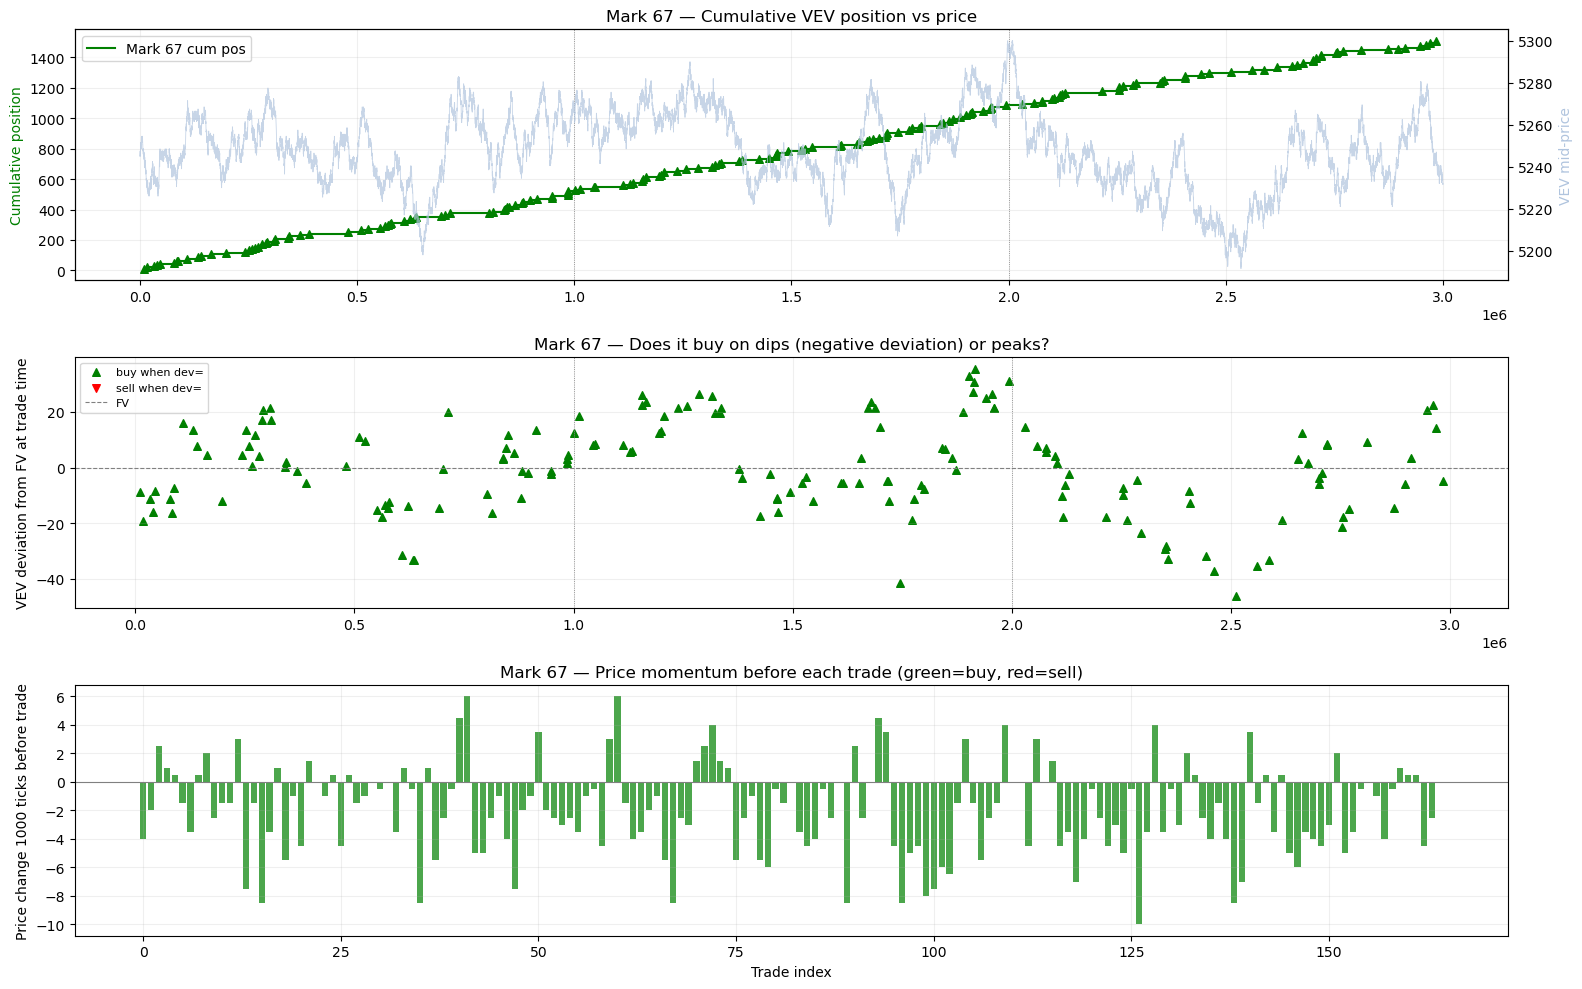

Mark 67 buys — avg deviation at trade: 0.09 (negative=dip, positive=peak)
Mark 67 sells— avg deviation at trade: nan
Mark 67 buys — avg momentum 1000t before: -1.96
Mark 67 sells— avg momentum 1000t before: nan


In [14]:
VEV_FV = 5248.39  # round 3 FV (baseline)

vev_price = prices[prices['product'] == 'VELVETFRUIT_EXTRACT'][['abs_ts','mid_price']].set_index('abs_ts')
m67 = te[(te['symbol'] == 'VELVETFRUIT_EXTRACT') & ((te['buyer'] == 'Mark 67') | (te['seller'] == 'Mark 67'))].copy()
m67['signed_qty'] = m67.apply(lambda r: r['quantity'] if r['buyer'] == 'Mark 67' else -r['quantity'], axis=1)
m67 = m67.sort_values('abs_ts')
m67['cum_pos'] = m67['signed_qty'].cumsum()

# look-back: price change in previous N ticks before trade
LOOKBACK = 1000
m67['price_change_before'] = m67.apply(
    lambda r: r['mid_price'] - vev_price['mid_price'].get(
        vev_price.index[vev_price.index.get_indexer([r['abs_ts'] - LOOKBACK], method='nearest')[0]], r['mid_price']),
    axis=1)

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=False)

# 1. cumulative position over time
ax = axes[0]
vev_ts = vev_price.reset_index()
ax2 = ax.twinx()
ax2.plot(vev_ts['abs_ts'], vev_ts['mid_price'], color='lightsteelblue', lw=0.6, alpha=0.7)
ax.step(m67['abs_ts'], m67['cum_pos'], color='green', lw=1.5, where='post', label='Mark 67 cum pos')
ax.scatter(m67[m67['signed_qty'] > 0]['abs_ts'], m67[m67['signed_qty'] > 0]['cum_pos'],
           color='green', marker='^', s=30, zorder=3)
ax.scatter(m67[m67['signed_qty'] < 0]['abs_ts'], m67[m67['signed_qty'] < 0]['cum_pos'],
           color='red', marker='v', s=30, zorder=3)
for xb in day_boundaries:
    ax.axvline(xb, color='grey', lw=0.6, ls=':')
ax.set_ylabel('Cumulative position', color='green')
ax2.set_ylabel('VEV mid-price', color='lightsteelblue')
ax.set_title('Mark 67 — Cumulative VEV position vs price')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.2)

# 2. trade price vs FV deviation at trade time
ax = axes[1]
m67_buys  = m67[m67['signed_qty'] > 0]
m67_sells = m67[m67['signed_qty'] < 0]
dev_buys  = m67_buys['mid_price']  - VEV_FV
dev_sells = m67_sells['mid_price'] - VEV_FV
ax.scatter(m67_buys['abs_ts'],  dev_buys,  color='green', marker='^', s=30, label='buy when dev=')
ax.scatter(m67_sells['abs_ts'], dev_sells, color='red',   marker='v', s=30, label='sell when dev=')
ax.axhline(0, color='grey', lw=0.8, ls='--', label='FV')
for xb in day_boundaries:
    ax.axvline(xb, color='grey', lw=0.6, ls=':')
ax.set_ylabel('VEV deviation from FV at trade time')
ax.set_title('Mark 67 — Does it buy on dips (negative deviation) or peaks?')
ax.legend(fontsize=8); ax.grid(True, alpha=0.2)

# 3. price momentum before each trade
ax = axes[2]
colors = ['green' if q > 0 else 'red' for q in m67['signed_qty']]
ax.bar(range(len(m67)), m67['price_change_before'], color=colors, alpha=0.7)
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlabel('Trade index')
ax.set_ylabel(f'Price change {LOOKBACK} ticks before trade')
ax.set_title(f'Mark 67 — Price momentum before each trade (green=buy, red=sell)')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Mark 67 buys — avg deviation at trade: {dev_buys.mean():.2f} (negative=dip, positive=peak)")
print(f"Mark 67 sells— avg deviation at trade: {dev_sells.mean():.2f}")
print(f"Mark 67 buys — avg momentum {LOOKBACK}t before: {m67[m67['signed_qty']>0]['price_change_before'].mean():.2f}")
print(f"Mark 67 sells— avg momentum {LOOKBACK}t before: {m67[m67['signed_qty']<0]['price_change_before'].mean():.2f}")

## Mark 01 vs Mark 22 — options accumulation race
Mark 01 systematically buys options; Mark 22 systematically sells. Are they always counterparties, or is there a third party involved?

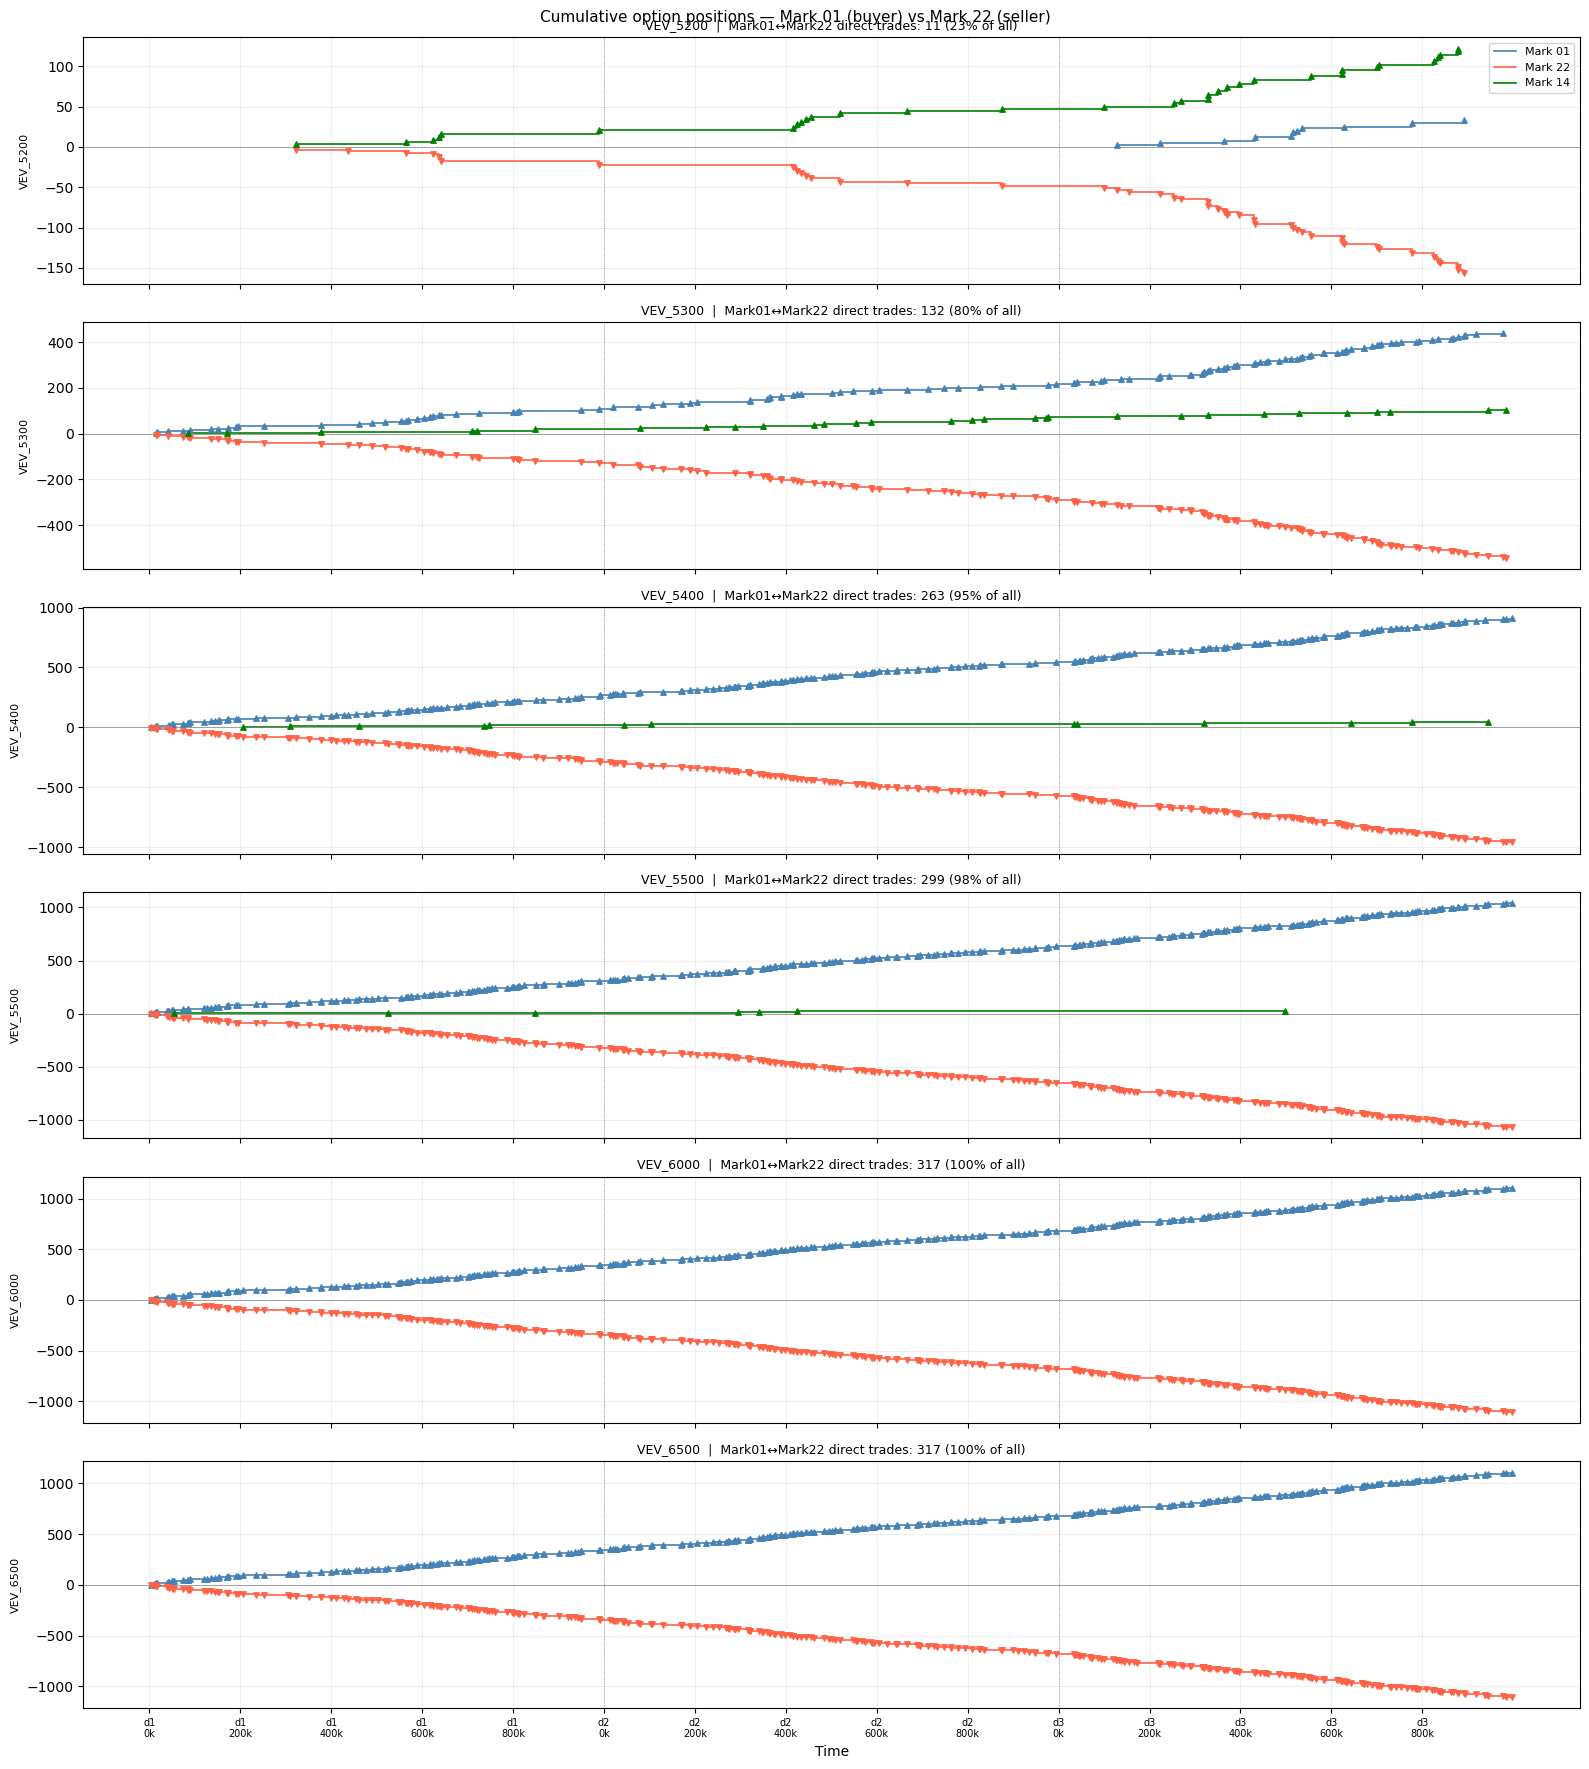

In [15]:
ACTIVE_STRIKES = ['VEV_5200','VEV_5300','VEV_5400','VEV_5500','VEV_6000','VEV_6500']

fig, axes = plt.subplots(len(ACTIVE_STRIKES), 1, figsize=(16, 3 * len(ACTIVE_STRIKES)), sharex=True)

for ax, prod in zip(axes, ACTIVE_STRIKES):
    opt_p = te[te['symbol'] == prod].sort_values('abs_ts')

    for bot, color in [('Mark 01', 'steelblue'), ('Mark 22', 'tomato'), ('Mark 14', 'green')]:
        bot_trades = opt_p[(opt_p['buyer'] == bot) | (opt_p['seller'] == bot)].copy()
        if bot_trades.empty:
            continue
        bot_trades['signed'] = bot_trades.apply(
            lambda r: r['quantity'] if r['buyer'] == bot else -r['quantity'], axis=1)
        bot_trades['cum'] = bot_trades['signed'].cumsum()
        ax.step(bot_trades['abs_ts'], bot_trades['cum'], color=color, lw=1.2, where='post', label=bot)
        ax.scatter(bot_trades[bot_trades['signed'] > 0]['abs_ts'],
                   bot_trades[bot_trades['signed'] > 0]['cum'], color=color, marker='^', s=15, zorder=3)
        ax.scatter(bot_trades[bot_trades['signed'] < 0]['abs_ts'],
                   bot_trades[bot_trades['signed'] < 0]['cum'], color=color, marker='v', s=15, zorder=3)

    # check if 01 and 22 are direct counterparties
    direct = opt_p[((opt_p['buyer'] == 'Mark 01') & (opt_p['seller'] == 'Mark 22')) |
                   ((opt_p['buyer'] == 'Mark 22') & (opt_p['seller'] == 'Mark 01'))]
    pct = len(direct) / len(opt_p) * 100 if len(opt_p) > 0 else 0

    for xb in day_boundaries:
        ax.axvline(xb, color='grey', lw=0.6, ls=':')
    ax.axhline(0, color='grey', lw=0.5)
    ax.set_ylabel(prod, fontsize=8)
    ax.grid(True, alpha=0.2)
    ax.set_title(f'{prod}  |  Mark01↔Mark22 direct trades: {len(direct)} ({pct:.0f}% of all)', fontsize=9)
    if ax == axes[0]:
        ax.legend(fontsize=8)

pos2, lbl2 = make_xticks(MAX_TS)
axes[-1].set_xticks(pos2); axes[-1].set_xticklabels(lbl2, fontsize=7)
axes[-1].set_xlabel('Time')
plt.suptitle('Cumulative option positions — Mark 01 (buyer) vs Mark 22 (seller)', fontsize=11)
plt.tight_layout()
plt.show()

## Mark 55 — VEV market maker analysis
Mark 55 has by far the highest VEV volume (6551) but tiny net (-43). Genuinely two-sided, or hiding a directional bet?

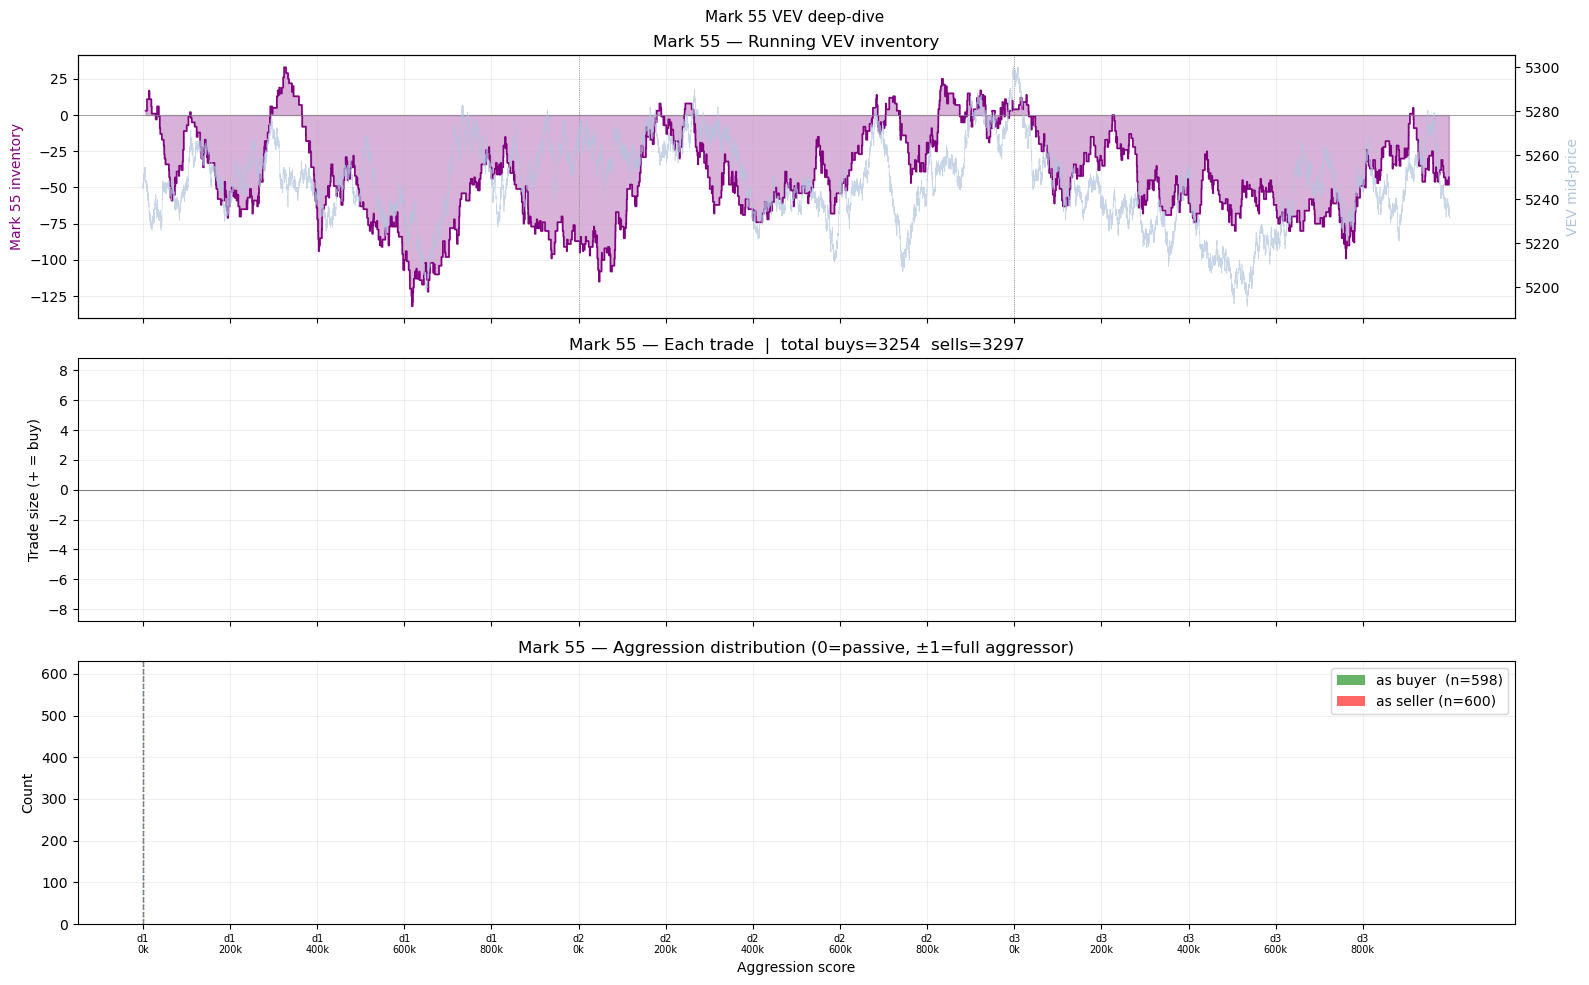

Mark 55 buy  aggression mean: 1.000
Mark 55 sell aggression mean: 1.000
Peak inventory: min=-132  max=33


In [16]:
m55 = te[(te['symbol'] == 'VELVETFRUIT_EXTRACT') & ((te['buyer'] == 'Mark 55') | (te['seller'] == 'Mark 55'))].copy()
m55['signed_qty'] = m55.apply(lambda r: r['quantity'] if r['buyer'] == 'Mark 55' else -r['quantity'], axis=1)
m55 = m55.sort_values('abs_ts')
m55['cum_pos'] = m55['signed_qty'].cumsum()

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)

# 1. Inventory over time vs price
ax = axes[0]; ax2 = ax.twinx()
ax2.plot(vev_ts['abs_ts'], vev_ts['mid_price'], color='lightsteelblue', lw=0.5, alpha=0.7)
ax.fill_between(m55['abs_ts'], m55['cum_pos'], alpha=0.3, color='purple', step='post')
ax.step(m55['abs_ts'], m55['cum_pos'], color='purple', lw=1.2, where='post')
ax.axhline(0, color='grey', lw=0.5)
for xb in day_boundaries: ax.axvline(xb, color='grey', lw=0.6, ls=':')
ax.set_ylabel('Mark 55 inventory', color='purple')
ax2.set_ylabel('VEV mid-price', color='lightsteelblue')
ax.set_title('Mark 55 — Running VEV inventory')
ax.grid(True, alpha=0.2)

# 2. Trade size distribution
ax = axes[1]
ax.bar(range(len(m55)), m55['signed_qty'],
       color=['green' if q > 0 else 'red' for q in m55['signed_qty']], alpha=0.7)
ax.axhline(0, color='grey', lw=0.8)
ax.set_ylabel('Trade size (+ = buy)')
ax.set_title(f'Mark 55 — Each trade  |  total buys={m55[m55["signed_qty"]>0]["quantity"].sum()}  sells={m55[m55["signed_qty"]<0]["quantity"].abs().sum()}')
ax.grid(True, alpha=0.2)

# 3. Aggression score distribution
ax = axes[2]
m55_agg_buy  = m55[m55['signed_qty'] > 0]['buyer_aggression']
m55_agg_sell = m55[m55['signed_qty'] < 0]['seller_aggression']
bins = np.linspace(-2, 2, 30)
ax.hist(m55_agg_buy,  bins=bins, color='green', alpha=0.6, label=f'as buyer  (n={len(m55_agg_buy)})')
ax.hist(m55_agg_sell, bins=bins, color='red',   alpha=0.6, label=f'as seller (n={len(m55_agg_sell)})')
ax.axvline(0, color='grey', lw=1, ls='--'); ax.axvline(1, color='orange', lw=1, ls=':'); ax.axvline(-1, color='steelblue', lw=1, ls=':')
ax.set_xlabel('Aggression score'); ax.set_ylabel('Count')
ax.set_title('Mark 55 — Aggression distribution (0=passive, ±1=full aggressor)')
ax.legend(); ax.grid(True, alpha=0.2)

pos2, lbl2 = make_xticks(MAX_TS)
axes[-1].set_xticks(pos2); axes[-1].set_xticklabels(lbl2, fontsize=7)
plt.suptitle('Mark 55 VEV deep-dive', fontsize=11)
plt.tight_layout()
plt.show()

print(f"Mark 55 buy  aggression mean: {m55_agg_buy.mean():.3f}")
print(f"Mark 55 sell aggression mean: {m55_agg_sell.mean():.3f}")
print(f"Peak inventory: min={m55['cum_pos'].min()}  max={m55['cum_pos'].max()}")

## Bot trade size distributions

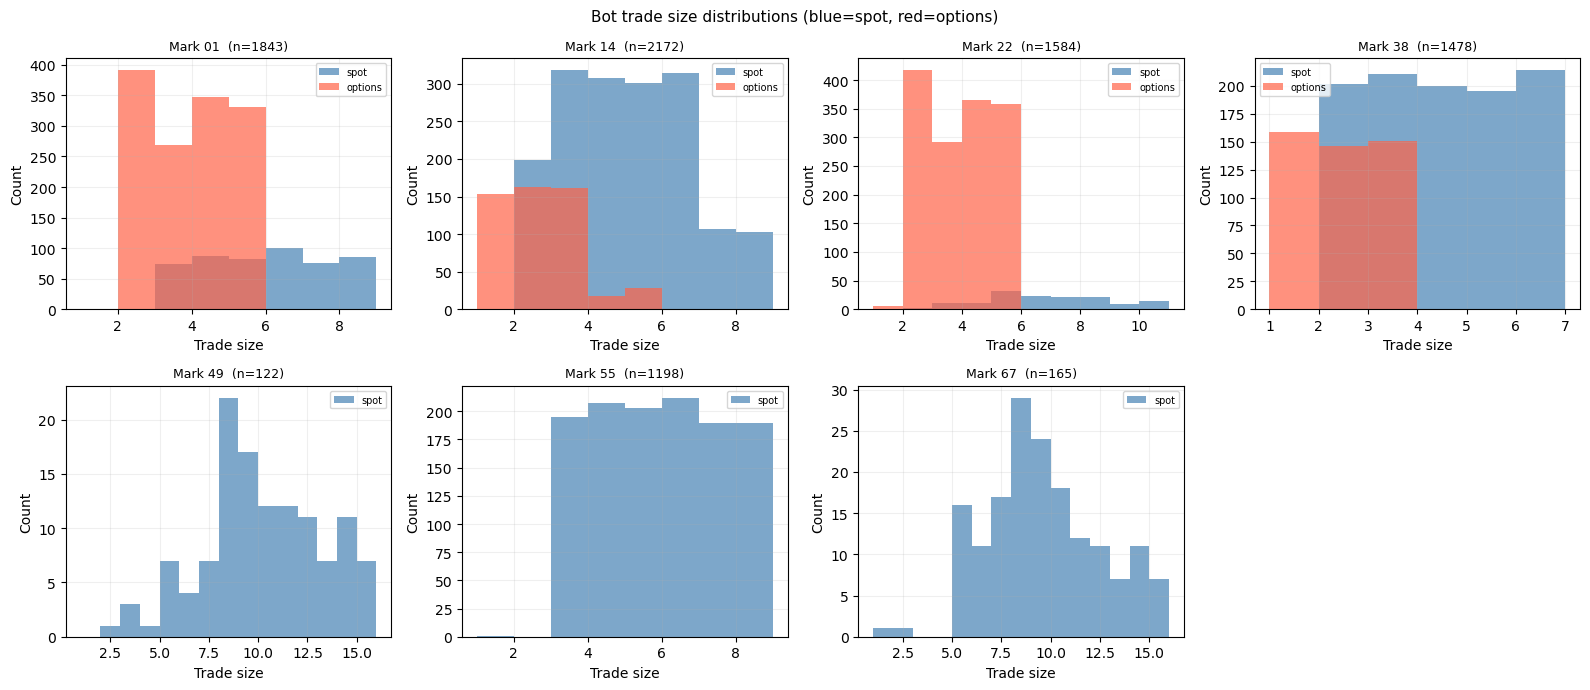

,min,median,mean,max,n_trades
bot,,,,,
Mark 01,2,4.0,4.0,8,1843
Mark 14,1,4.0,4.0,8,2172
Mark 22,1,4.0,3.7,10,1584
Mark 38,1,3.0,3.4,6,1478
Mark 49,2,9.0,9.7,15,122
Mark 55,1,5.0,5.5,8,1198
Mark 67,1,9.0,9.2,15,165


In [17]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=False)
axes = axes.flatten()

for i, bot in enumerate(BOTS):
    ax = axes[i]
    bot_trades = trades[(trades['buyer'] == bot) | (trades['seller'] == bot)]
    if bot_trades.empty:
        ax.set_visible(False)
        continue
    # break down by product category
    spot  = bot_trades[bot_trades['symbol'].isin(['VELVETFRUIT_EXTRACT','HYDROGEL_PACK'])]
    opts  = bot_trades[~bot_trades['symbol'].isin(['VELVETFRUIT_EXTRACT','HYDROGEL_PACK'])]

    bins = range(1, bot_trades['quantity'].max() + 2)
    if len(spot) > 0:
        ax.hist(spot['quantity'], bins=bins, color='steelblue', alpha=0.7, label='spot')
    if len(opts) > 0:
        ax.hist(opts['quantity'], bins=bins, color='tomato', alpha=0.7, label='options')
    ax.set_title(f'{bot}  (n={len(bot_trades)})', fontsize=9)
    ax.set_xlabel('Trade size'); ax.set_ylabel('Count')
    ax.legend(fontsize=7); ax.grid(True, alpha=0.2)

# summary table
size_rows = []
for bot in BOTS:
    bt = trades[(trades['buyer'] == bot) | (trades['seller'] == bot)]
    if bt.empty: continue
    size_rows.append({'bot': bot, 'min': bt['quantity'].min(), 'median': bt['quantity'].median(),
                      'mean': round(bt['quantity'].mean(),1), 'max': bt['quantity'].max(),
                      'n_trades': len(bt)})
axes[-1].axis('off')
plt.suptitle('Bot trade size distributions (blue=spot, red=options)', fontsize=11)
plt.tight_layout()
plt.show()
pd.DataFrame(size_rows).set_index('bot')

## Bot activity timing — when do bots trade?
Rolling trade count per 10k-tick window, per bot. Reveals whether bots are active throughout the day or burst-trade at specific times.

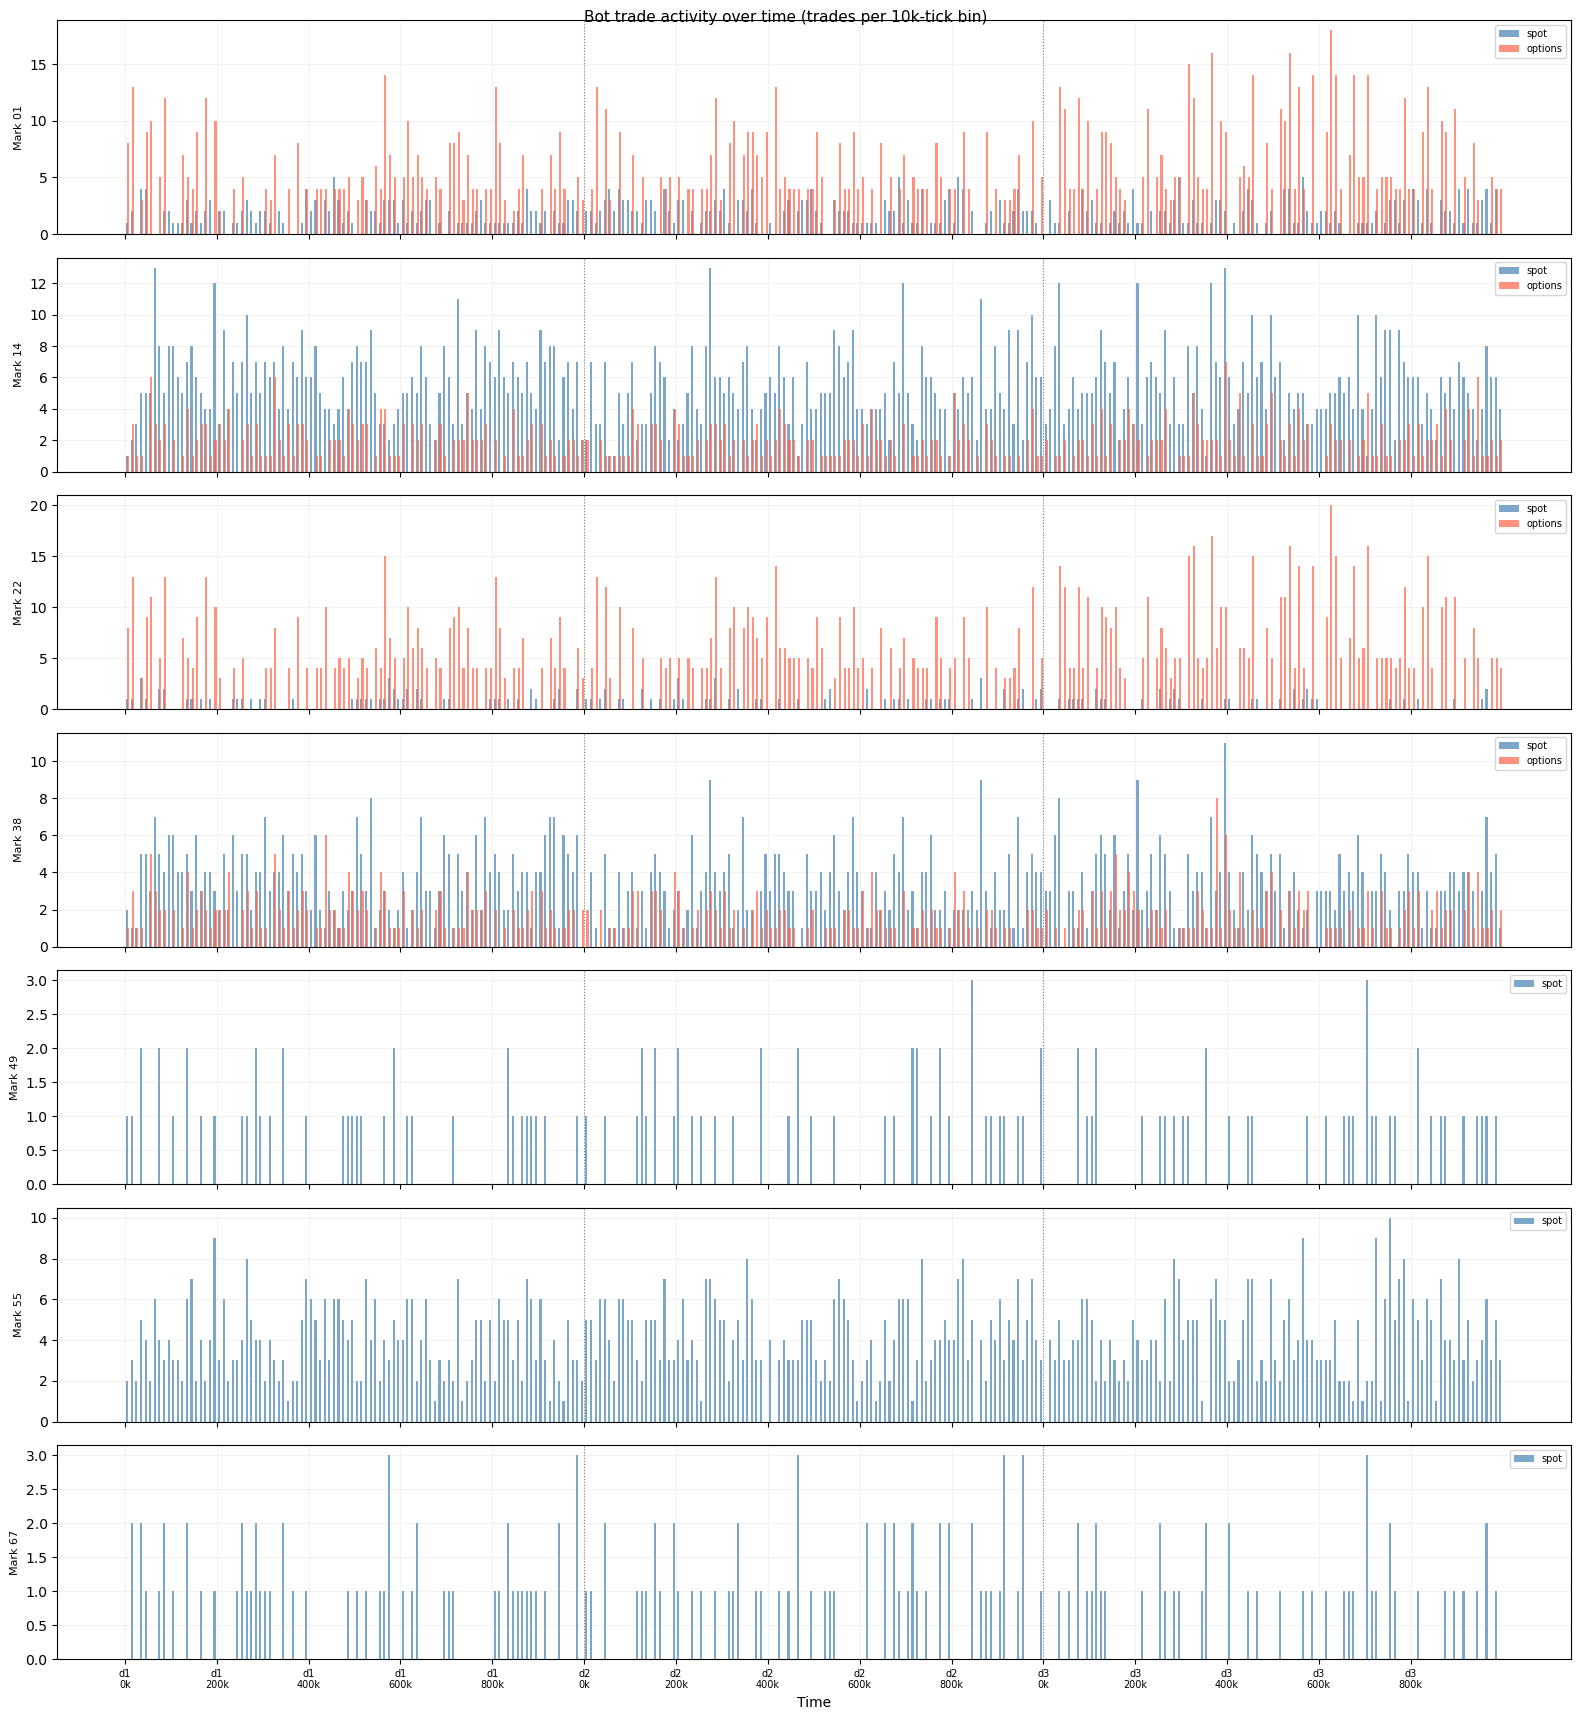

In [18]:
BIN_SIZE = 10_000
bins_ts = np.arange(0, MAX_TS + BIN_SIZE, BIN_SIZE)
bin_centers = (bins_ts[:-1] + bins_ts[1:]) / 2

fig, axes = plt.subplots(len(BOTS), 1, figsize=(16, 2.5 * len(BOTS)), sharex=True)

for ax, bot in zip(axes, BOTS):
    bot_all = trades[(trades['buyer'] == bot) | (trades['seller'] == bot)]
    # separate spot vs options
    spot_ts = bot_all[bot_all['symbol'].isin(['VELVETFRUIT_EXTRACT','HYDROGEL_PACK'])]['abs_ts']
    opt_ts  = bot_all[~bot_all['symbol'].isin(['VELVETFRUIT_EXTRACT','HYDROGEL_PACK'])]['abs_ts']

    if len(spot_ts) > 0:
        counts_s, _ = np.histogram(spot_ts, bins=bins_ts)
        ax.bar(bin_centers, counts_s, width=BIN_SIZE*0.45, color='steelblue', alpha=0.7, label='spot')
    if len(opt_ts) > 0:
        counts_o, _ = np.histogram(opt_ts, bins=bins_ts)
        ax.bar(bin_centers, counts_o, width=BIN_SIZE*0.45, align='edge', color='tomato', alpha=0.7, label='options')

    for xb in day_boundaries:
        ax.axvline(xb, color='grey', lw=0.8, ls=':')
    ax.set_ylabel(bot, fontsize=8)
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, alpha=0.15)

pos2, lbl2 = make_xticks(MAX_TS, step=200_000)
axes[-1].set_xticks(pos2); axes[-1].set_xticklabels(lbl2, fontsize=7)
axes[-1].set_xlabel('Time')
plt.suptitle('Bot trade activity over time (trades per 10k-tick bin)', fontsize=11)
plt.tight_layout()
plt.show()